# 1.Prepare Data for Analysis

In [2]:
# importing all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [3]:
# Read it as a csv file and store it asa DataFrame named df
df = pd.read_csv('Sales.csv')
print("The file loaded successfully")

The file loaded successfully


In [4]:
# Print the data frame
df.head()

,Date,Time,State,Group,Unit,Sales
0,01-Oct-20,Morning,WA,Kids,8,20000
1,01-Oct-20,Morning,WA,Men,8,20000
2,01-Oct-20,Morning,WA,Women,4,10000
3,01-Oct-20,Morning,WA,Seniors,15,37500
4,01-Oct-20,Afternoon,WA,Kids,3,7500


In [6]:
# Print the shape of dataframe
# df.shape O/P (7560, 6)
(row, col) = df.shape
print(f"The Dataframe has {row} rows and {col} columns")

The Dataframe has 7560 rows and 6 columns


In [ ]:
# Check for missing values
df.isnull().sum() # .sum() → counts per column

## There are no missing values in the DataFrame

In [8]:
total_missing_values = df.isnull().sum().sum()
# First .sum() → counts per column
# Second .sum() → adds all column counts together
print("Total missing value in the dataframe are : ", total_missing_values) 

Total missing value in the dataframe are :  0


In [9]:
# Verify that there are no non missing values
no_non_missing_values = df.notnull().sum().sum()
print("The totan no non missing values are :",no_non_missing_values)

The totan no non missing values are : 45360


# 2.Normalize Data for Analysis

In [10]:
df.head()

,Date,Time,State,Group,Unit,Sales
0,01-Oct-20,Morning,WA,Kids,8,20000
1,01-Oct-20,Morning,WA,Men,8,20000
2,01-Oct-20,Morning,WA,Women,4,10000
3,01-Oct-20,Morning,WA,Seniors,15,37500
4,01-Oct-20,Afternoon,WA,Kids,3,7500


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    7560 non-null   object
 1   Time    7560 non-null   object
 2   State   7560 non-null   object
 3   Group   7560 non-null   object
 4   Unit    7560 non-null   int64 
 5   Sales   7560 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 354.5+ KB


In [14]:
# Create a new DataFrame df_data_only from DataFrame
df_data_only = df[['Unit', 'Sales']].copy()
df_data_only.head()

#Outer brackets → tell pandas “select columns”,df[  [ column_list ]  ]
#Inner brackets → list of column names,df[ list_of_columns ]

,Unit,Sales
0,8,20000
1,8,20000
2,4,10000
3,15,37500
4,3,7500


In [15]:
#Age is small (0–100)
#Salary is big (0–100000)
#some ML models get confused because big numbers dominate small numbers.
#So we scale them.there are 2 ways
#Normalization (Min-Max Scaling)
#Example:
#Values: 10, 20, 30
#After normalization:10 → 0,20 → 0.5,30 → 1
#Everything becomes between 0 and 1.
#Standardization (Z-Score Scaling)
# Meaning:Convert values so:
#Mean = 0
#Standard deviation = 1
#After standardization:Some values become negative,
#Some positive,Center is 0
# Min Max scalar - Normalization
#Standard scalar - standardization

In [18]:
# Normalize the data
from sklearn.preprocessing import MinMaxScaler #import scaler
scalar = MinMaxScaler() # create scaler object
# created scaling machine is empty not seen the data yet

normalize_data = scalar.fit_transform(df_data_only) # fit()knows min and max,transform()applies formula
# now all the values btn 0 and 1.the o/p is numpy not a dataframe
normalize_data_df = pd.DataFrame(normalize_data, columns=['Unit', 'Sales']) # convert back to df
normalize_data_df.head()

,Unit,Sales
0,0.095238,0.095238
1,0.095238,0.095238
2,0.031746,0.031746
3,0.206349,0.206349
4,0.015873,0.015873


In [44]:
normalize_data_df['Unit'].min(), normalize_data_df['Unit'].max() # verified values btn 0 and 1

(0.0, 0.9999999999999999)

In [20]:
normalize_data_df['Sales'].min(), normalize_data_df['Sales'].max() # verified values btn 0 and 1

(0.0, 1.0)

In [22]:
print("Before Normalization")
print(df_data_only['Unit'].min(), df_data_only['Unit'].max())
print("After Normalization")
print(normalize_data_df['Unit'].min(), normalize_data_df['Unit'].max())



Before Normalization
2 65
After Normalization
0.0 0.9999999999999999


In [24]:
print("Before Normalization")
print(df_data_only['Sales'].min(), df_data_only['Sales'].max())
print("After Normalization")
print(normalize_data_df['Sales'].min(), normalize_data_df['Sales'].max())


Before Normalization
5000 162500
After Normalization
0.0 1.0


# 3.Visualize the overall trend


# Convert date column to datetime
df['Date'] = pd.to_datetime(df['Date'], format = "%d-%b-%y")
# %d-day1-31,%b- short month,%y-2 digit year
# if we don't convert we cannot extract,groupby or calculate time difference
df.info()

In [27]:
# Group by the date and sum unit and sales
# data aggregation work
# group all rows that have same date together
# ["Unit", "Sales"]- only work with these two columns
daily_data = df.groupby('Date')[["Unit", "Sales"]].sum().reset_index()
daily_data

,Date,Unit,Sales
0,2020-10-01,1488,3720000
1,2020-10-02,1486,3715000
2,2020-10-03,1556,3890000
3,2020-10-04,1488,3720000
4,2020-10-05,1545,3862500
...,...,...,...
85,2020-12-26,1886,4715000
86,2020-12-27,1855,4637500
87,2020-12-28,1838,4595000
88,2020-12-29,1843,4607500


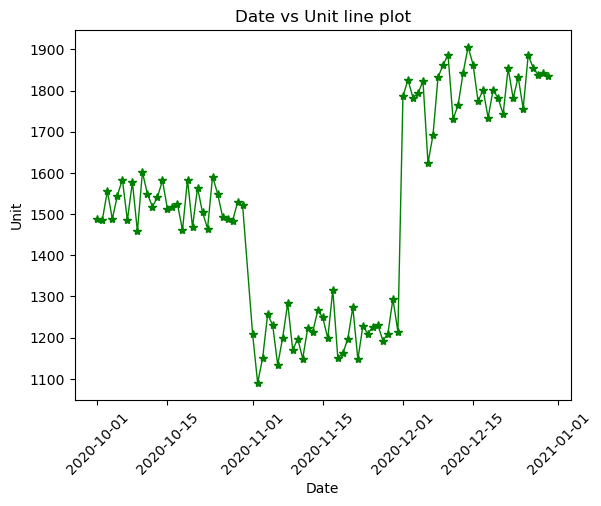

In [33]:
# Plot the graph between date and unit
plt.plot(daily_data['Date'], daily_data['Unit'], color = 'g', linewidth = 1, marker = "*")
plt.title("Date vs Unit line plot") #plotting units sold per date over time
# linewidth- makes the line thicker
plt.xlabel('Date') # these three lines
plt.ylabel('Unit')
plt.tick_params(axis = 'x', rotation = 45) # since x axis values are overlapping we add this line
plt.show()


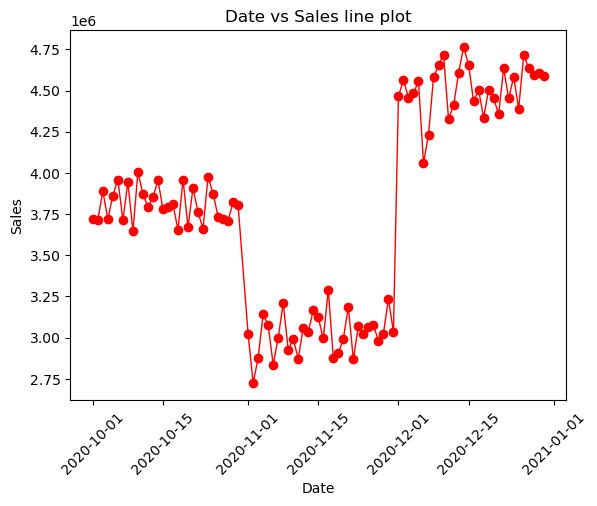

In [35]:
# Plot the graph between date and sales
plt.plot(daily_data['Date'], daily_data['Sales'], color='r',linewidth = 1, marker = "o")
plt.title("Date vs Sales line plot") #plotting units sold per date over time
# linewidth- makes the line thicker
plt.xlabel('Date') # these three lines
plt.ylabel('Sales')
plt.tick_params(axis = 'x', rotation = 45) # since x axis values are overlapping we add this line
plt.show()


#### It is very clear from the line plot that the overall sales
#### goes down in the month of November

# 4.Analyze Monthly Data

In [38]:
# Chunk the quaterly data into monthly data
df_oct = df.loc[(df['Date'] >= '2020-10-1') & (df['Date'] < '2020-11-1')].copy()
df_oct.head()

# another style
#start = pd.Timestamp('2020-10-01')
#end   = pd.Timestamp('2020-11-01')

#df_oct = df.loc[(df['Date'] >= start) & (df['Date'] < end)].copy()
#df_oct.head()

,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,8,20000
1,2020-10-01,Morning,WA,Men,8,20000
2,2020-10-01,Morning,WA,Women,4,10000
3,2020-10-01,Morning,WA,Seniors,15,37500
4,2020-10-01,Afternoon,WA,Kids,3,7500


In [39]:
#df_nov = df.loc[(df['Date'] >= '2020-11-1') & (df['Date'] < '2020-12-1')].copy()
#df_nov.head()
start = pd.Timestamp('2020-11-01')
end   = pd.Timestamp('2020-12-01')

df_nov = df.loc[(df['Date'] >= start) & (df['Date'] < end)].copy()
df_nov.head()

,Date,Time,State,Group,Unit,Sales
2520,2020-11-01,Morning,WA,Kids,4,10000
2521,2020-11-01,Morning,WA,Men,6,15000
2522,2020-11-01,Morning,WA,Women,4,10000
2523,2020-11-01,Morning,WA,Seniors,7,17500
2524,2020-11-01,Afternoon,WA,Kids,8,20000


In [40]:
start = pd.Timestamp('2020-12-01')
end   = pd.Timestamp('2021-01-01')

df_dec = df.loc[(df['Date'] >= start) & (df['Date'] < end)].copy()
df_dec.head()

,Date,Time,State,Group,Unit,Sales
5040,2020-12-01,Morning,WA,Kids,9,22500
5041,2020-12-01,Morning,WA,Men,11,27500
5042,2020-12-01,Morning,WA,Women,15,37500
5043,2020-12-01,Morning,WA,Seniors,13,32500
5044,2020-12-01,Afternoon,WA,Kids,13,32500


In [42]:
print("Summary of Monthly dData")
print("=======================================================")
print(f"Number of records in October : {len(df_oct)}")
print(f"Number of records in November : {len(df_nov)}")
print(f"Number of records in December : {len(df_dec)}")




Summary of Monthly dData
Number of records in October : 2520
Number of records in November : 2520
Number of records in December : 2520


# 5.Describe Data

In [43]:
# Describe entire dataset
df.describe(include = 'all')

,Date,Time,State,Group,Unit,Sales
count,7560,7560,7560,7560,7560.000000,7560.000000
unique,NaN,3,7,4,NaN,NaN
top,NaN,Morning,WA,Kids,NaN,NaN
freq,NaN,2520,1080,1890,NaN,NaN
mean,2020-11-15 04:00:00.000000256,NaN,NaN,NaN,18.005423,45013.558201
min,2020-10-01 00:00:00,NaN,NaN,NaN,2.000000,5000.000000
25%,2020-10-23 00:00:00,NaN,NaN,NaN,8.000000,20000.000000
50%,2020-11-15 12:00:00,NaN,NaN,NaN,14.000000,35000.000000
75%,2020-12-08 00:00:00,NaN,NaN,NaN,26.000000,65000.000000
max,2020-12-30 00:00:00,NaN,NaN,NaN,65.000000,162500.000000


In [45]:
# Description for October
df_oct.describe()

,Date,Unit,Sales
count,2520,2520.000000,2520.000000
mean,2020-10-15 12:00:00,18.141270,45353.174603
min,2020-10-01 00:00:00,3.000000,7500.000000
25%,2020-10-08 00:00:00,9.000000,22500.000000
50%,2020-10-15 12:00:00,14.000000,35000.000000
75%,2020-10-23 00:00:00,27.000000,67500.000000
max,2020-10-30 00:00:00,50.000000,125000.000000
std,NaN,11.944521,29861.302213


In [46]:
# Description for October
df_oct[["Unit", "Sales"]].describe()

,Unit,Sales
count,2520.000000,2520.000000
mean,18.141270,45353.174603
std,11.944521,29861.302213
min,3.000000,7500.000000
25%,9.000000,22500.000000
50%,14.000000,35000.000000
75%,27.000000,67500.000000
max,50.000000,125000.000000


In [48]:
# Description for November
df_nov[["Unit", "Sales"]].describe()

,Unit,Sales
count,2520.000000,2520.000000
mean,14.394048,35985.119048
std,10.946470,27366.175823
min,2.000000,5000.000000
25%,6.000000,15000.000000
50%,10.000000,25000.000000
75%,22.000000,55000.000000
max,45.000000,112500.000000


In [49]:
# Description for Deceember
df_dec[["Unit", "Sales"]].describe()

,Unit,Sales
count,2520.000000,2520.000000
mean,21.480952,53702.380952
std,14.554181,36385.451298
min,5.000000,12500.000000
25%,10.000000,25000.000000
50%,15.000000,37500.000000
75%,31.000000,77500.000000
max,65.000000,162500.000000


# 6.Analyze Unit Data


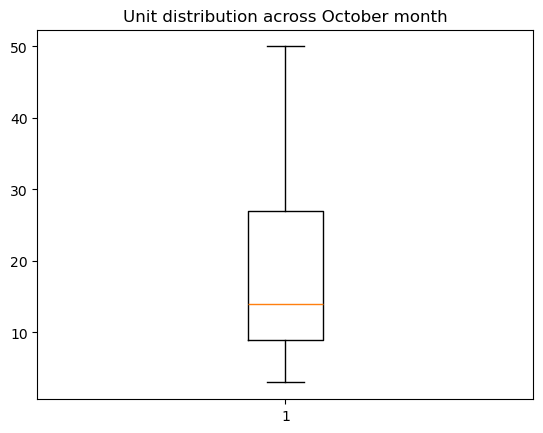

In [50]:
plt.boxplot(df_oct['Unit']) 
plt.title('Unit distribution across October month') 
plt.show()

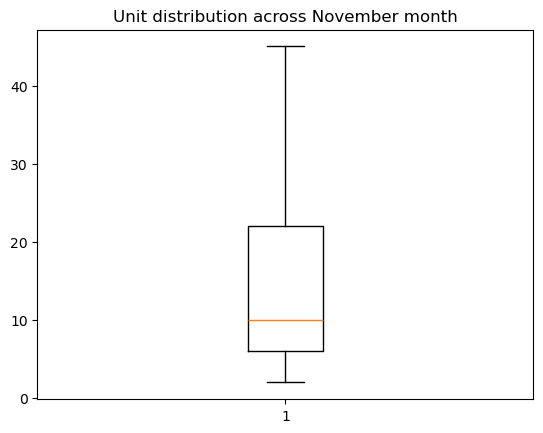

In [51]:
plt.boxplot(df_nov['Unit']) 
plt.title('Unit distribution across November month') 
plt.show()

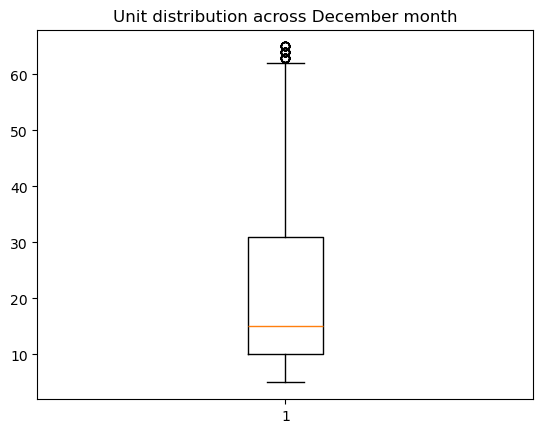

In [52]:
plt.boxplot(df_dec['Unit']) 
plt.title('Histogram distribution across December month') 
plt.show()

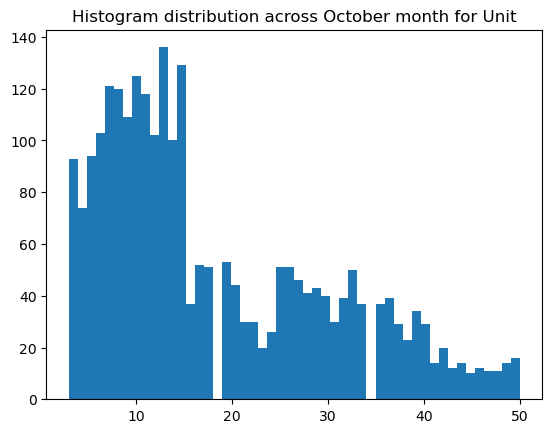

In [59]:
plt.hist(df_oct['Unit'], bins = 50) 
plt.title('Histogram distribution across October month for Unit') 
plt.show()

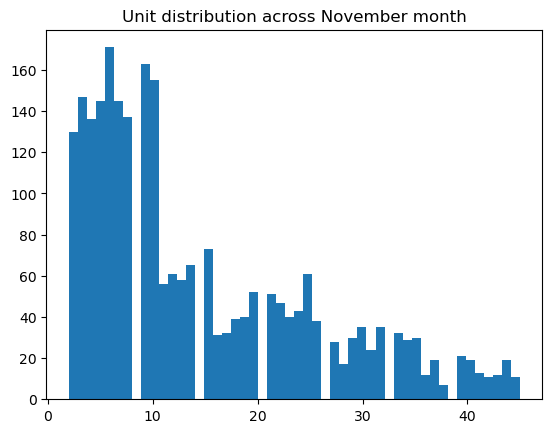

In [58]:
plt.hist(df_nov['Unit'], bins = 50) 
plt.title('Unit distribution across November month for Unit') 
plt.show()

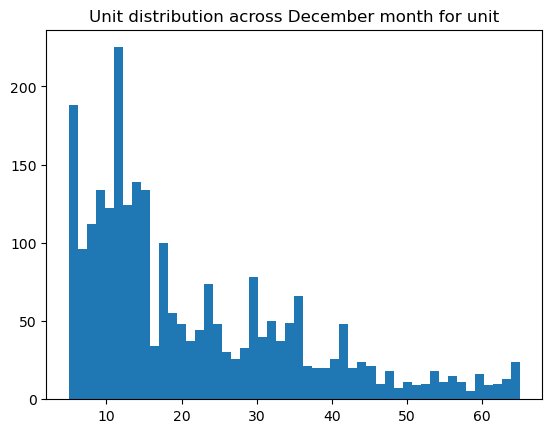

In [61]:
plt.hist(df_dec['Unit'], bins = 50) 
plt.title('Unit distribution across December month for unit') 
plt.show()

In [76]:
def extract_month_from_date(date):
    return date.strftime('%b')   
# % b gives month
#date   # o/p Timestamp('2020-10-01 00:00:00')
#date.strftime('%b')  #o/p - 'Oct'
# If we want to add a new colmn as month it contains oct,nov,and dec

In [77]:
date = df.loc[2750, 'Date']
#extract_month_from_date(date)
df['Month'] = df['Date'].apply(extract_month_from_date)
df.head(10)

,Date,Time,State,Group,Unit,Sales,Month
0,2020-10-01,Morning,WA,Kids,8,20000,Oct
1,2020-10-01,Morning,WA,Men,8,20000,Oct
2,2020-10-01,Morning,WA,Women,4,10000,Oct
3,2020-10-01,Morning,WA,Seniors,15,37500,Oct
4,2020-10-01,Afternoon,WA,Kids,3,7500,Oct
5,2020-10-01,Afternoon,WA,Men,10,25000,Oct
6,2020-10-01,Afternoon,WA,Women,3,7500,Oct
7,2020-10-01,Afternoon,WA,Seniors,11,27500,Oct
8,2020-10-01,Evening,WA,Kids,15,37500,Oct
9,2020-10-01,Evening,WA,Men,15,37500,Oct


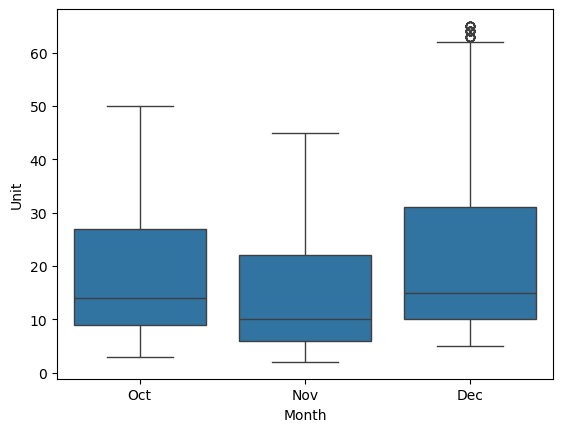

In [79]:
sns.boxplot(x ='Month', y ='Unit', data = df)
plt.show()

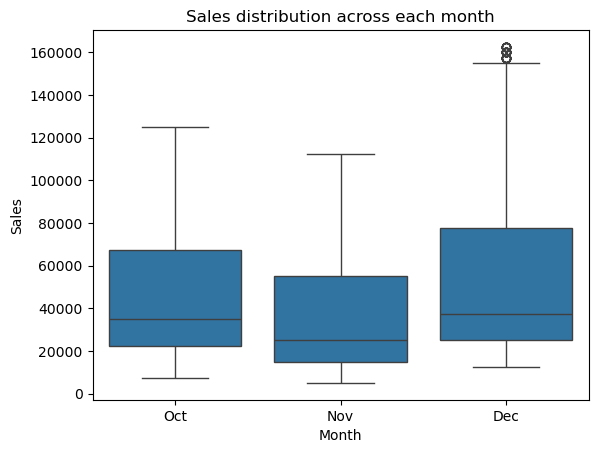

In [81]:
sns.boxplot(x ='Month', y ='Sales', data = df)
plt.title("Sales distribution across each month")
plt.show()

# 7.Explore Monthly Plots and Analysis

In [84]:
# Overall units and sales figures
print("=====================Unit Figure=======================")
print(f"Total units sold : {df['Unit'].sum()}")
print(f"Total sales : {df['Sales'].sum()}")

=====================Unit Figure=======================
Total units sold : 136121
Total sales : 340302500


In [83]:
# Units sold in Oct,Nov,Dec
print("=====================Unit Figure=======================")
print(f"Total units in October : {df_oct['Unit'].sum()}")
print(f"Total units in November : {df_nov['Unit'].sum()}")
print(f"Total units in December : {df_dec['Unit'].sum()}")

print("=====================Sales Figure=======================")
print(f"Total sales in October : {df_oct['Sales'].sum()}")
print(f"Total sales in November : {df_nov['Sales'].sum()}")
print(f"Total sales in December : {df_dec['Sales'].sum()}")


=====================Unit Figure=======================
Total units in October : 45716
Total units in November : 36273
Total units in December : 54132
=====================Sales Figure=======================
Total sales in October : 114290000
Total sales in November : 90682500
Total sales in December : 135330000


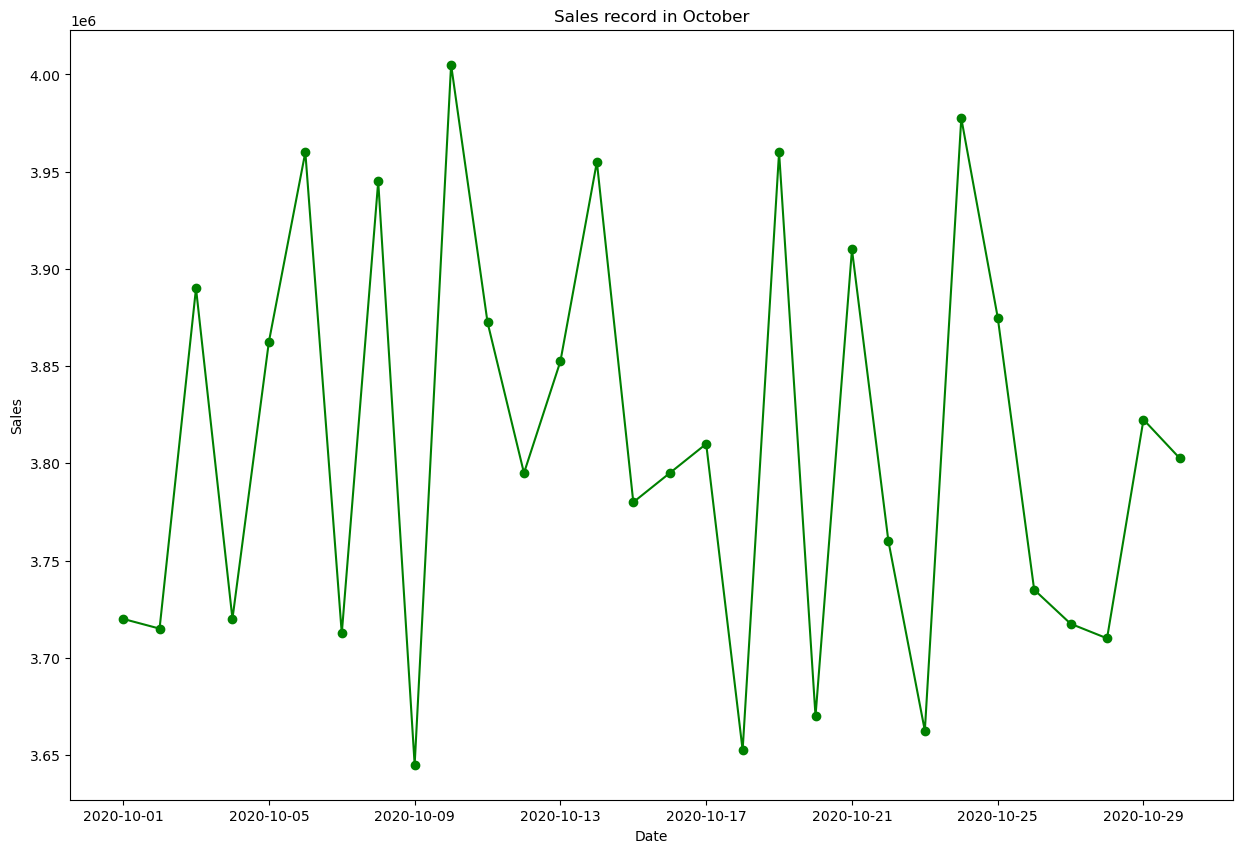

In [88]:
df_oct_sales = df_oct.groupby('Date')['Sales'].sum().reset_index()

# Consolidated 3-months sales plot
plt.figure(figsize = (15, 10))
plt.plot(df_oct_sales['Date'], df_oct_sales['Sales'], color = 'g', marker = 'o')
plt.title('Sales record in October')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

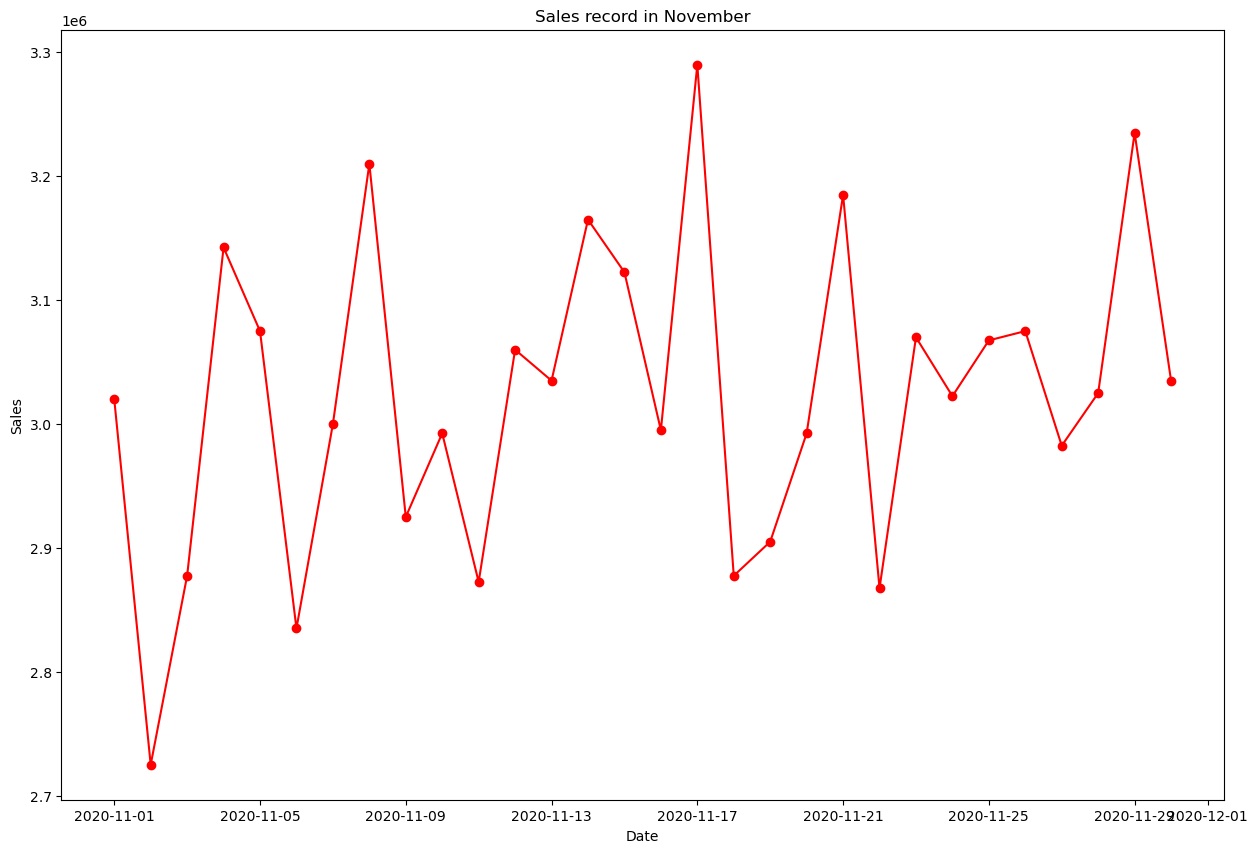

In [89]:
df_nov_sales = df_nov.groupby('Date')['Sales'].sum().reset_index()

# Consolidated 3-months sales plot
plt.figure(figsize = (15, 10))
plt.plot(df_nov_sales['Date'], df_nov_sales['Sales'], color = 'r', marker = 'o')
plt.title('Sales record in November')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

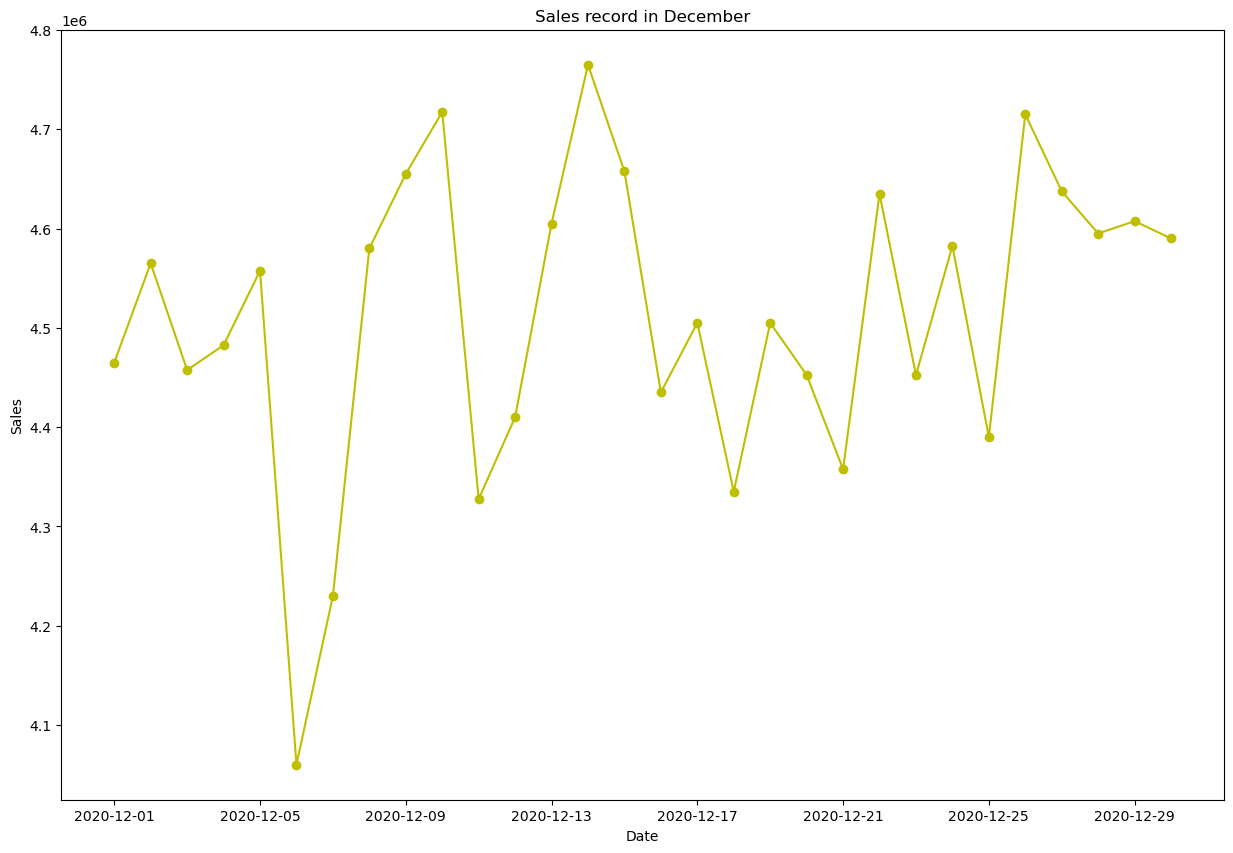

In [92]:
df_dec_sales = df_dec.groupby('Date')['Sales'].sum().reset_index()

# Consolidated 3-months sales plot
plt.figure(figsize = (15, 10))
plt.plot(df_dec_sales['Date'], df_dec_sales['Sales'], color = 'y', marker = 'o')
plt.title('Sales record in December')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

In [99]:
# Extract the day number in month
def extract_date_from_datetime(date):
    return date.strftime("%d")
df_oct["Day"] = df_oct["Date"].apply(extract_date_from_datetime)
df_oct_sale_daywise = df_oct.groupby('Day')['Sales'].sum().reset_index()
df_oct_sale_daywise.rename(columns = {'Sales': 'Oct_Sales'}, inplace=True)

df_nov["Day"] = df_nov["Date"].apply(extract_date_from_datetime)
df_nov_sale_daywise = df_nov.groupby('Day')['Sales'].sum().reset_index()
df_nov_sale_daywise.rename(columns = {'Sales': 'Nov_Sales'}, inplace=True)

df_dec["Day"] = df_dec["Date"].apply(extract_date_from_datetime)
df_dec_sale_daywise = df_dec.groupby('Day')['Sales'].sum().reset_index()
df_dec_sale_daywise.rename(columns = {'Sales': 'Dec_Sales'}, inplace=True)


In [100]:
df_oct_sale_daywise.head()

,Day,Oct_Sales
0,01,3720000
1,02,3715000
2,03,3890000
3,04,3720000
4,05,3862500


In [101]:
df_nov_sale_daywise.head()

,Day,Nov_Sales
0,01,3020000
1,02,2725000
2,03,2877500
3,04,3142500
4,05,3075000


In [102]:
df_dec_sale_daywise.head()

,Day,Dec_Sales
0,01,4465000
1,02,4565000
2,03,4457500
3,04,4482500
4,05,4557500


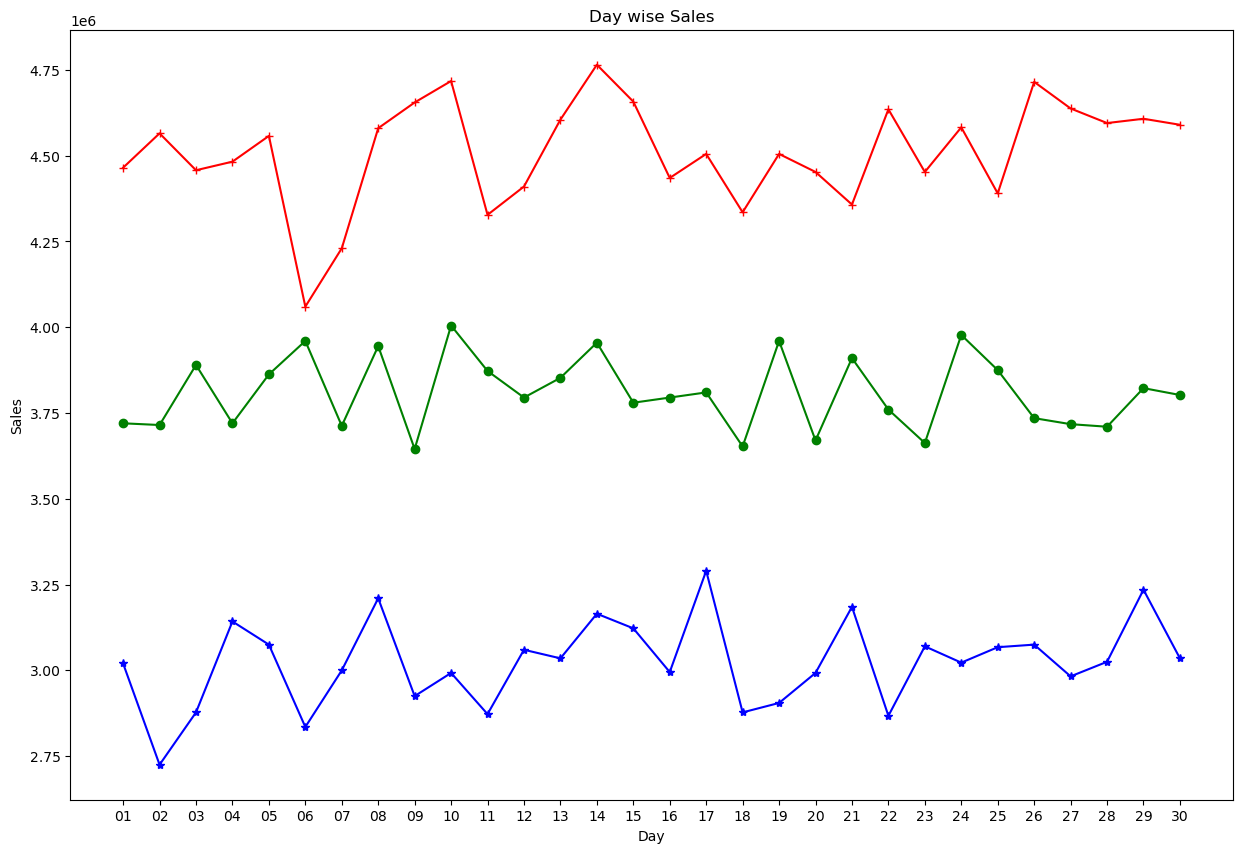

In [112]:

plt.figure(figsize = (15, 10))
plt.plot(df_oct_sale_daywise['Day'], df_oct_sale_daywise['Oct_Sales'], color = 'g', marker = 'o')
plt.plot(df_nov_sale_daywise['Day'], df_nov_sale_daywise['Nov_Sales'], color = 'b', marker = '*')
plt.plot(df_dec_sale_daywise['Day'], df_dec_sale_daywise['Dec_Sales'], color = 'r', marker = '+')
plt.title('Day wise Sales')
plt.xlabel('Day')
plt.ylabel('Sales')
plt.show()

In [116]:
# Extract the day number of week
def extract_weekday_from_datetime(date):
    return date.strftime("%a")
    
df_oct["WeekDay"] = df_oct["Date"].apply(extract_weekday_from_datetime)
df_oct_sale_daywise = df_oct.groupby('WeekDay')['Sales'].sum().reset_index()
df_oct_sale_daywise.rename(columns = {'Sales': 'Oct_Sales'}, inplace=True)

df_nov["WeekDay"] = df_nov["Date"].apply(extract_weekday_from_datetime)
df_nov_sale_daywise = df_nov.groupby('WeekDay')['Sales'].sum().reset_index()
df_nov_sale_daywise.rename(columns = {'Sales': 'Nov_Sales'}, inplace=True)

df_dec["WeekDay"] = df_dec["Date"].apply(extract_weekday_from_datetime)
df_dec_sale_daywise = df_dec.groupby('WeekDay')['Sales'].sum().reset_index()
df_dec_sale_daywise.rename(columns = {'Sales': 'Dec_Sales'}, inplace=True)


In [118]:
df_oct_sale_daywise

,WeekDay,Oct_Sales
0,Fri,18620000
1,Mon,15352500
2,Sat,15682500
3,Sun,15120000
4,Thu,19027500
5,Tue,15200000
6,Wed,15287500


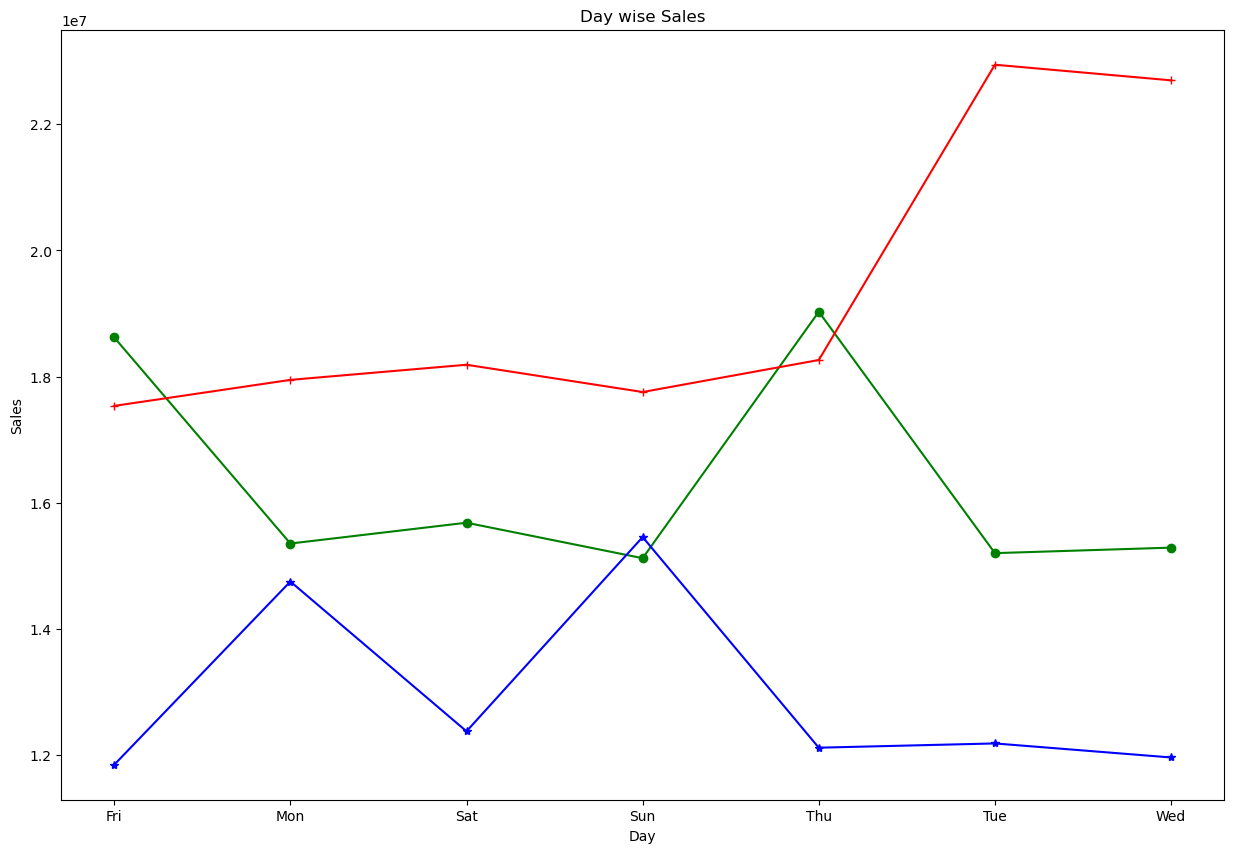

In [119]:
plt.figure(figsize = (15, 10))
plt.plot(df_oct_sale_daywise['WeekDay'], df_oct_sale_daywise['Oct_Sales'], color = 'g', marker = 'o')
plt.plot(df_nov_sale_daywise['WeekDay'], df_nov_sale_daywise['Nov_Sales'], color = 'b', marker = '*')
plt.plot(df_dec_sale_daywise['WeekDay'], df_dec_sale_daywise['Dec_Sales'], color = 'r', marker = '+')
plt.title('Day wise Sales')
plt.xlabel('Day')
plt.ylabel('Sales')
plt.show()

# Obtain a Comprehensive Snapshot

In [126]:
# Overall metric of data
total_record = len(df)
total_units = df['Unit'].sum()
total_sales = df['Sales'].sum()
average_units = df['Unit'].mean()
average_sales = df['Sales'].mean()

print("===============Overall Data Matrics===============")
print(f"Total number of records : {total_record}")
print(f"Total Units : {total_units}")
print(f"Total Sales : {total_sales}")
print(f"Average number of units : {average_units}")
print(f"Average Sales : {average_sales}")
print()
print("===============Overall Data Matrics for October===============")
print(f"Total number of records : {len(df_oct)}")
print(f"Total Units : {df_oct['Unit'].sum()}")
print(f"Total Sales : {df_oct['Sales'].sum()}")
print(f"Average number of units : {df_oct['Unit'].mean()}")
print(f"Average Sales : {df_oct['Sales'].mean()}")
print()
print("===============Overall Data Matrics for November===============")
print(f"Total number of records : {len(df_nov)}")
print(f"Total Units : {df_nov['Unit'].sum()}")
print(f"Total Sales : {df_nov['Sales'].sum()}")
print(f"Average number of units : {df_nov['Unit'].mean()}")
print(f"Average Sales : {df_nov['Sales'].mean()}")
print()
print("===============Overall Data Matrics for December===============")
print(f"Total number of records : {len(df_oct)}")
print(f"Total Units : {df_dec['Unit'].sum()}")
print(f"Total Sales : {df_dec['Sales'].sum()}")
print(f"Average number of units : {df_dec['Unit'].mean()}")
print(f"Average Sales : {df_dec['Sales'].mean()}")


===============Overall Data Matrics===============
Total number of records : 7560
Total Units : 136121
Total Sales : 340302500
Average number of units : 18.00542328042328
Average Sales : 45013.5582010582

===============Overall Data Matrics for October===============
Total number of records : 2520
Total Units : 45716
Total Sales : 114290000
Average number of units : 18.141269841269843
Average Sales : 45353.1746031746

===============Overall Data Matrics for November===============
Total number of records : 2520
Total Units : 36273
Total Sales : 90682500
Average number of units : 14.394047619047619
Average Sales : 35985.119047619046

===============Overall Data Matrics for December===============
Total number of records : 2520
Total Units : 54132
Total Sales : 135330000
Average number of units : 21.48095238095238
Average Sales : 53702.380952380954


# 9.Analyze Statewise Sales in United States

In [127]:
df.head()

,Date,Time,State,Group,Unit,Sales,Month
0,2020-10-01,Morning,WA,Kids,8,20000,Oct
1,2020-10-01,Morning,WA,Men,8,20000,Oct
2,2020-10-01,Morning,WA,Women,4,10000,Oct
3,2020-10-01,Morning,WA,Seniors,15,37500,Oct
4,2020-10-01,Afternoon,WA,Kids,3,7500,Oct


In [128]:
df['State'].unique()

array([' WA', 'AZ', 'FL', 'KY', 'CA', 'NY', 'TX'], dtype=object)

In [133]:
state_wise_data = df.groupby('State')[['Unit', 'Sales']].sum().reset_index()
state_wise_data

,State,Unit,Sales
0,WA,8861,22152500
1,AZ,9032,22580000
2,CA,13367,33417500
3,FL,23543,58857500
4,KY,42226,105565000
5,NY,29988,74970000
6,TX,9104,22760000


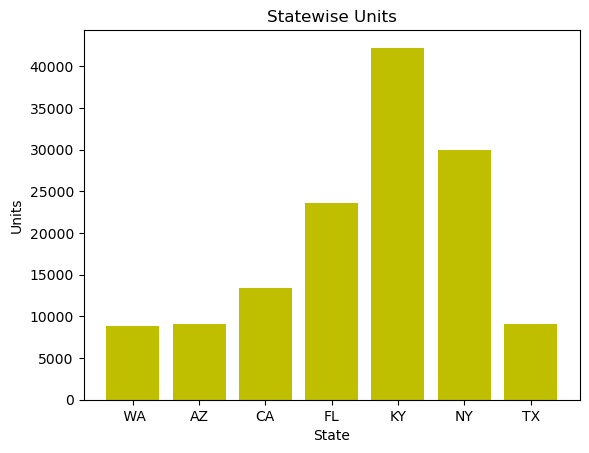

In [137]:
plt.bar(state_wise_data['State'], state_wise_data['Unit'], color = 'y')
plt.title('Statewise Units')
plt.xlabel('State')
plt.ylabel('Units')
plt.show()

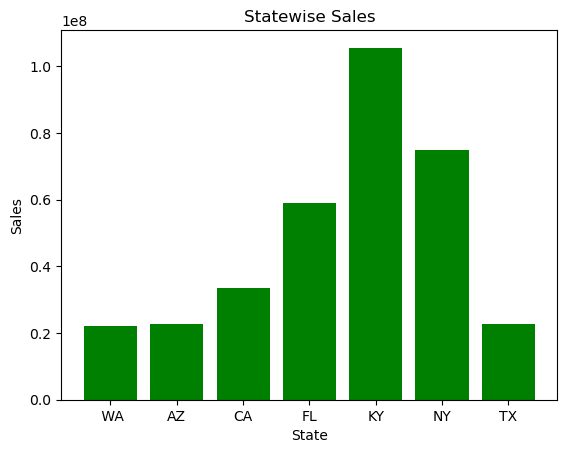

In [138]:
plt.bar(state_wise_data['State'], state_wise_data['Sales'], color = 'g')
plt.title('Statewise Sales')
plt.xlabel('State')
plt.ylabel('Sales')
plt.show()

#